In [15]:
display("text/html", "<style>.container { width:100% !important; }</style>")

To do (probably in separate notebooks):
- Make a 2 by 7 figure of Heaps' law across all these systems.
- Make a 2 by 7 figure of many of the rank-frequency distributions for all of these.
- 

# Let's take a look at the Grilli data

In [2]:
using DataFrames, CSV, Plots, LaTeXStrings, DelimitedFiles, GLM

In [3]:
Plots.theme(:dao)

In [4]:
include("./diversity-simulator.jl")
using .dsim

In [5]:
pal = cgrad(:tol_muted);
cpal10 = [pal[i] for i in 0.0:1/46:1]

In [6]:
length(cpal10)

In [7]:
read_data = CSV.read("./Data_csv/Grilli-crosssecdata__datatax.csv", DataFrame)
# first split on classification
gd1 = groupby(read_data, :classification);

In [16]:
read_data

Row,otu_id,count,project_id,sample_id,run_id,nreads,classification
,Int64,Float64,String15,String15,String15,Float64,String
1,107380,7.0,MGYS00002437,SRS2822941,SRR6457279,73003.0,seawater
2,149885,1.0,MGYS00002437,SRS2822941,SRR6457279,73003.0,seawater
3,118090,6.0,MGYS00002437,SRS2822941,SRR6457279,73003.0,seawater
4,103181,854.0,MGYS00002437,SRS2822941,SRR6457279,73003.0,seawater
5,83222,1.0,MGYS00002437,SRS2822941,SRR6457279,73003.0,seawater
6,57104,9.0,MGYS00002437,SRS2822941,SRR6457279,73003.0,seawater
7,219738,2.0,MGYS00002437,SRS2822941,SRR6457279,73003.0,seawater
8,242743,1.0,MGYS00002437,SRS2822941,SRR6457279,73003.0,seawater
9,176063,4.0,MGYS00002437,SRS2822941,SRR6457279,73003.0,seawater


In [8]:
gd1;

For each classification, split up on the sample.

In [9]:
gd_classes = []
for gd in gd1
    push!(gd_classes, groupby(gd, :sample_id))
end

In [92]:
length.(gd_classes)

14-element Vector{Int64}:
 476
  93
 316
  22
 112
 509
 465
 991
  30
  25
 188
 198
  57
 575

In [110]:
gd_classes[8]

Row,otu_id,count,project_id,sample_id,run_id,nreads,classification
,Int64,Float64,String15,String15,String15,Float64,String
1,131704,1.0,ERP021896,ERS1579579,ERR1868423,1.0,skin
2,103181,150.0,ERP021896,ERS1579579,ERR1868423,1.0,skin
3,57104,1.0,ERP021896,ERS1579579,ERR1868423,1.0,skin
4,219738,2.0,ERP021896,ERS1579579,ERR1868423,1.0,skin
5,47921,1.0,ERP021896,ERS1579579,ERR1868423,1.0,skin
6,5336,21.0,ERP021896,ERS1579579,ERR1868423,1.0,skin
7,237652,7.0,ERP021896,ERS1579579,ERR1868423,1.0,skin
8,71141,1.0,ERP021896,ERS1579579,ERR1868423,1.0,skin
9,49601,3.0,ERP021896,ERS1579579,ERR1868423,1.0,skin


# Class 1: Seawater

Make a plot of the diversity versus the size.

In [51]:
scatter(sum.([x[!,:count] for x in gd_classes[1]]), length.([x[!,:count] for x in gd_classes[1]]), xaxis = :log, yaxis = :log, alpha = 0.1);

In [112]:
logxs = log10.(sum.([x[!,:count] for x in gd_classes[1]]))
logys = log10.(length.([x[!,:count] for x in gd_classes[1]]));

In [113]:
df = DataFrame(y = logys, x = logxs);

In [114]:
glm = lm(@formula(y ~ x), df)

StatsModels.TableRegressionModel{LinearModel{GLM.LmResp{Vector{Float64}}, GLM.DensePredChol{Float64, LinearAlgebra.CholeskyPivoted{Float64, Matrix{Float64}, Vector{Int64}}}}, Matrix{Float64}}

y ~ 1 + x

Coefficients:
────────────────────────────────────────────────────────────────────────
                Coef.  Std. Error      t  Pr(>|t|)  Lower 95%  Upper 95%
────────────────────────────────────────────────────────────────────────
(Intercept)  0.661884   0.127708    5.18    <1e-06   0.410939   0.912828
x            0.354613   0.0260115  13.63    <1e-35   0.303501   0.405726
────────────────────────────────────────────────────────────────────────

In [115]:
coef(glm)

2-element Vector{Float64}:
 0.6618836043834962
 0.3546134703391564

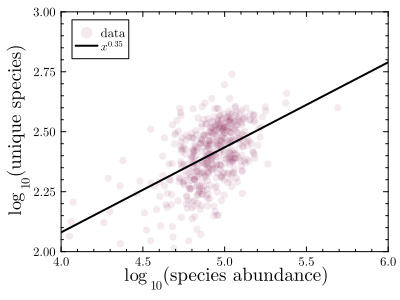

In [116]:
scatter(log10.(sum.([x[!,:count] for x in gd_classes[1]])), log10.(length.([x[!,:count] for x in gd_classes[1]])), alpha = 0.1, label = "data", c = pal[8]);
plot!(collect(0:7),coef(glm)[1] .+ collect(0:7) .*coef(glm)[2], label = L"x^{%$(round(coef(glm)[2],digits = 2))}", color = :black, lw = 2)
plot!(xlims = [4,6], ylims = [2,3], ylabel = L"$\log_{10}$(unique species)", xlabel = L"$\log_{10}$(species abundance)", legend = :topleft,
    size = (400,300), grid = :none, minorgrid = :none)

Now let's make the rank-frequency plots.

In [123]:
si = sortperm(length.([x[!,:count] for x in gd_classes[1]]), rev = true);

In [124]:
cpal = [pal[i] for i in 0.0:1/10:1];

In [125]:
scatter(sort(gd_classes[1][si[1]][!,:count]./sum(gd_classes[1][si[1]][!,:count]), rev = true), xaxis = :log, yaxis = :log, color = cpal[1], alpha = 0.1)
for i in 2:10
    scatter!(sort(gd_classes[1][si[i]][!,:count]./sum(gd_classes[1][si[i]][!,:count]), rev = true), color = cpal[i], alpha = 0.1)
end
scatter!(legend = :none, ylabel = "norm. freq.", xlabel = "rank", size = (400,300), grid = :none, minorgrid = :none);

# Class 3: Gut

Make a plot of the diversity versus the size.

In [75]:
scatter(sum.([x[!,:count] for x in gd_classes[3]]), length.([x[!,:count] for x in gd_classes[3]]), xaxis = :log, yaxis = :log, alpha = 0.1);

In [76]:
logxs = log10.(sum.([x[!,:count] for x in gd_classes[3]]))
logys = log10.(length.([x[!,:count] for x in gd_classes[3]]));

In [77]:
df = DataFrame(y = logys, x = logxs);

In [78]:
glm = lm(@formula(y ~ x), df)

StatsModels.TableRegressionModel{LinearModel{GLM.LmResp{Vector{Float64}}, GLM.DensePredChol{Float64, LinearAlgebra.CholeskyPivoted{Float64, Matrix{Float64}, Vector{Int64}}}}, Matrix{Float64}}

y ~ 1 + x

Coefficients:
────────────────────────────────────────────────────────────────────────
                Coef.  Std. Error      t  Pr(>|t|)  Lower 95%  Upper 95%
────────────────────────────────────────────────────────────────────────
(Intercept)  1.93071   0.0452827   42.64    <1e-99   1.84162    2.01981
x            0.306202  0.00947086  32.33    <1e-99   0.287567   0.324836
────────────────────────────────────────────────────────────────────────

In [79]:
coef(glm)

2-element Vector{Float64}:
 1.9307115781457154
 0.3062016487678795

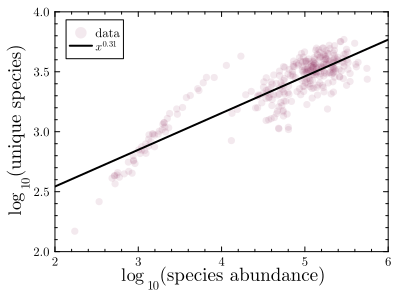

In [84]:
scatter(log10.(sum.([x[!,:count] for x in gd_classes[3]])), log10.(length.([x[!,:count] for x in gd_classes[3]])), alpha = 0.1, label = "data", c = pal[8]);
plot!(collect(0:7),coef(glm)[1] .+ collect(0:7) .*coef(glm)[2], label = L"x^{%$(round(coef(glm)[2],digits = 2))}", color = :black, lw = 2)
plot!(xlims = [2,6], ylims = [2,4], ylabel = L"$\log_{10}$(unique species)", xlabel = L"$\log_{10}$(species abundance)", legend = :topleft,
    size = (400,300), grid = :none, minorgrid = :none)

Now let's make the rank-frequency plots.

In [85]:
si = sortperm(length.([x[!,:count] for x in gd_classes[3]]), rev = true);

In [86]:
cpal = [pal[i] for i in 0.0:1/10:1];

In [89]:
scatter(sort(gd_classes[3][si[1]][!,:count]./sum(gd_classes[3][si[1]][!,:count]), rev = true), xaxis = :log, yaxis = :log, color = cpal[1], alpha = 0.1)
for i in 2:10
    scatter!(sort(gd_classes[3][si[i]][!,:count]./sum(gd_classes[3][si[i]][!,:count]), rev = true), color = cpal[i], alpha = 0.1)
end
scatter!(legend = :none, ylabel = "norm. freq.", xlabel = "rank", size = (400,300), grid = :none, minorgrid = :none);

# Class 3: Skin

Make a plot of the diversity versus the size.

In [94]:
scatter(sum.([x[!,:count] for x in gd_classes[8]]), length.([x[!,:count] for x in gd_classes[8]]), xaxis = :log, yaxis = :log, alpha = 0.1);

In [95]:
logxs = log10.(sum.([x[!,:count] for x in gd_classes[8]]))
logys = log10.(length.([x[!,:count] for x in gd_classes[8]]));

In [96]:
df = DataFrame(y = logys, x = logxs);

In [117]:
glm = lm(@formula(y ~ x), df)

StatsModels.TableRegressionModel{LinearModel{GLM.LmResp{Vector{Float64}}, GLM.DensePredChol{Float64, LinearAlgebra.CholeskyPivoted{Float64, Matrix{Float64}, Vector{Int64}}}}, Matrix{Float64}}

y ~ 1 + x

Coefficients:
────────────────────────────────────────────────────────────────────────
                Coef.  Std. Error      t  Pr(>|t|)  Lower 95%  Upper 95%
────────────────────────────────────────────────────────────────────────
(Intercept)  0.661884   0.127708    5.18    <1e-06   0.410939   0.912828
x            0.354613   0.0260115  13.63    <1e-35   0.303501   0.405726
────────────────────────────────────────────────────────────────────────

In [118]:
coef(glm)

2-element Vector{Float64}:
 0.6618836043834962
 0.3546134703391564

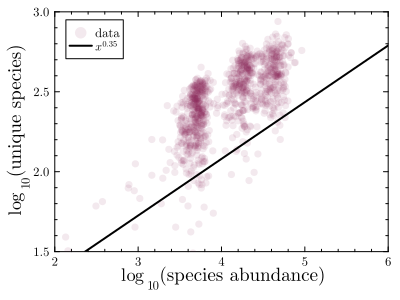

In [119]:
scatter(log10.(sum.([x[!,:count] for x in gd_classes[8]])), log10.(length.([x[!,:count] for x in gd_classes[8]])), alpha = 0.1, label = "data", c = pal[8]);
plot!(collect(0:7),coef(glm)[1] .+ collect(0:7) .*coef(glm)[2], label = L"x^{%$(round(coef(glm)[2],digits = 2))}", color = :black, lw = 2)
plot!(xlims = [2,6], ylims = [1.5,3], ylabel = L"$\log_{10}$(unique species)", xlabel = L"$\log_{10}$(species abundance)", legend = :topleft,
    size = (400,300), grid = :none, minorgrid = :none)

Now let's make the rank-frequency plots.

In [120]:
si = sortperm(length.([x[!,:count] for x in gd_classes[8]]), rev = true);

In [121]:
cpal = [pal[i] for i in 0.0:1/10:1];

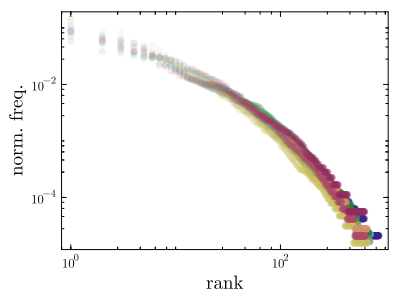

In [122]:
scatter(sort(gd_classes[8][si[1]][!,:count]./sum(gd_classes[8][si[1]][!,:count]), rev = true), xaxis = :log, yaxis = :log, color = cpal[1], alpha = 0.1)
for i in 2:10
    scatter!(sort(gd_classes[8][si[i]][!,:count]./sum(gd_classes[8][si[i]][!,:count]), rev = true), color = cpal[i], alpha = 0.1)
end
scatter!(legend = :none, ylabel = "norm. freq.", xlabel = "rank", size = (400,300), grid = :none, minorgrid = :none)